# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p4"
subproj <- "AVGUSTINOVA_04_05"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "KAZN"   "AUTS2"  "MALAT1" "NAV3"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.2

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

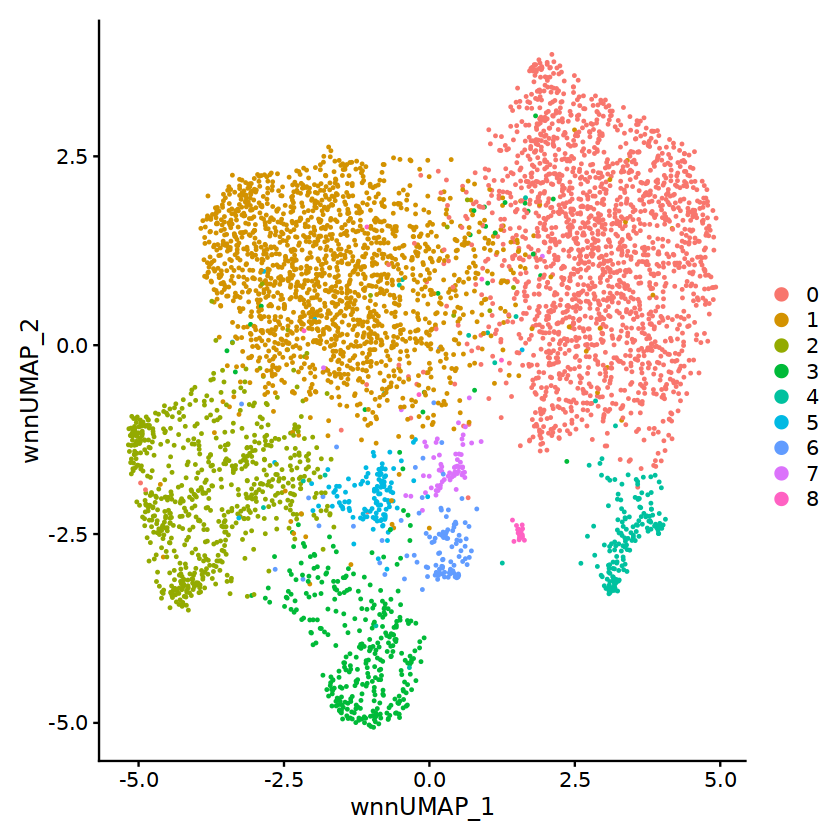

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

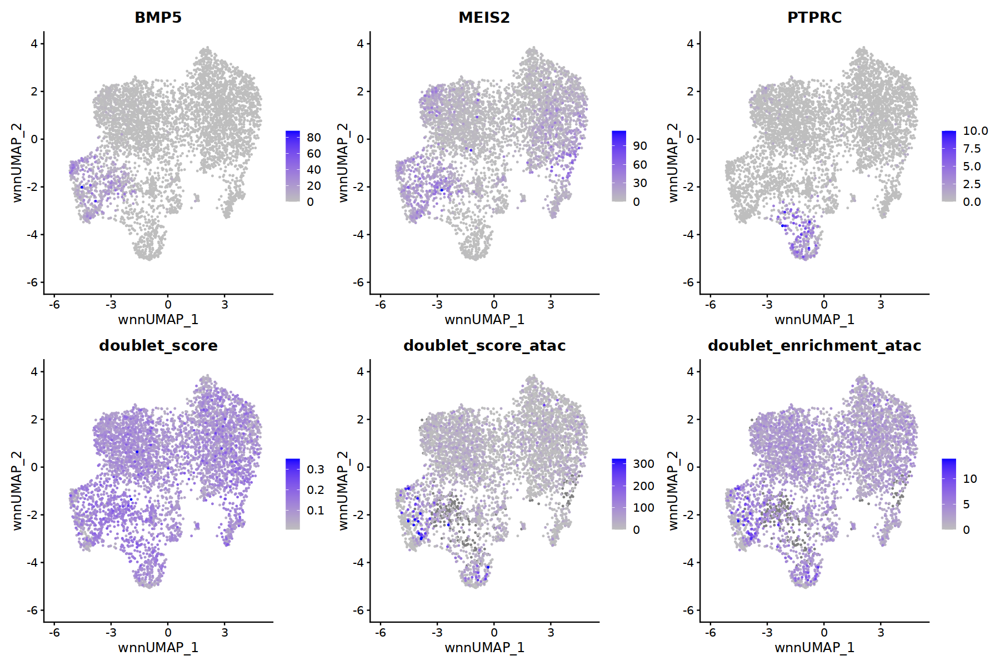

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("BMP5","MEIS2","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

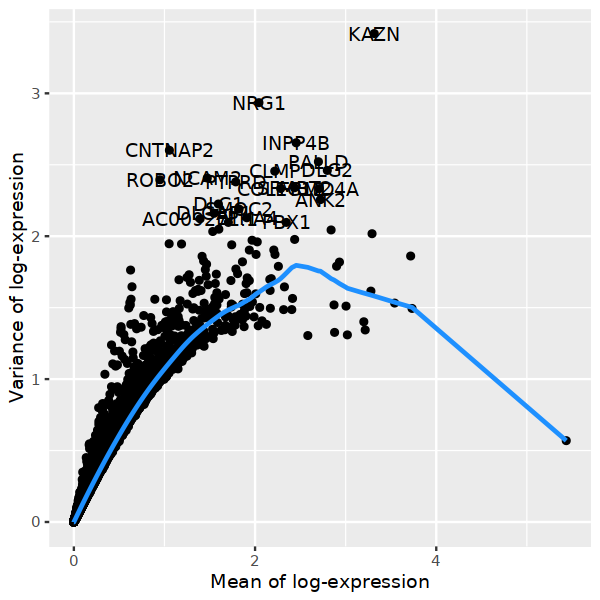

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 7593
[1] 7591


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  RORA, ANK2, SNTG2, EYA4, CLMP, LGR4, SMOC2, PTPRD, NCAM2, INPP4B 
	   COL12A1, NRG1, DLC1, TIMP3, PALLD, DLG2, KIAA1211, MAGI1, AC009271.1, DLGAP1 
	   SDK2, PDE3A, AC116362.1, HPSE2, AL139383.1, CNTNAP2, MEG8, KCNN3, ROBO2, TENM3 
Negative:  PLXDC2, LRMDA, DPYD, DOCK8, PTPRC, SLC8A1, LDLRAD4, RAB31, DOCK2, DOCK4 
	   DOCK5, MSR1, SAMSN1, ATXN1, CHST11, SLC16A10, FMNL2, ATP8B4, KYNU, FMN1 
	   RBM47, TRPS1, GLUL, IQGAP2, DOCK10, TBXAS1, VAV3, ABCA1, FAM49A, CTSB 
PC_ 2 
Positive:  SETBP1, CFH, NR2F1-AS1, BMP5, KCNT2, RARB, UNC5C, DMD, MDGA2, SEMA3D 
	   L3MBTL4, RALYL, PRICKLE1, AC092422.1, ADAMTS20, MIR548XHG, EPHA7, KIAA0825, TMPRSS15, PLEKHA5 
	   KCNK2, ARHGAP28, NR2F1, FSTL5, PLPP1, CNTNAP2, AC078881.1, COLGALT2, BNC2, ROBO2 
Negative:  SFMBT2, FRMD4A, INPP4B, PALLD, COLEC12, CLMP, DLG2, EPHA4, PTPRD, NRG1 
	   COL12A1, SMOC2, NHSL1, AC009271.1, SDK2, KCNN3, RORA, KIAA1211, AL139383.1, CAMK1D 
	   ESRRB, GRAMD1B, MEIS1, PRKAG2, 

In [19]:
markers = c("SMOC2","ANK2","SETBP1", "NRG1","BMP5","SEMA3D","PTPRC", "CD3D")

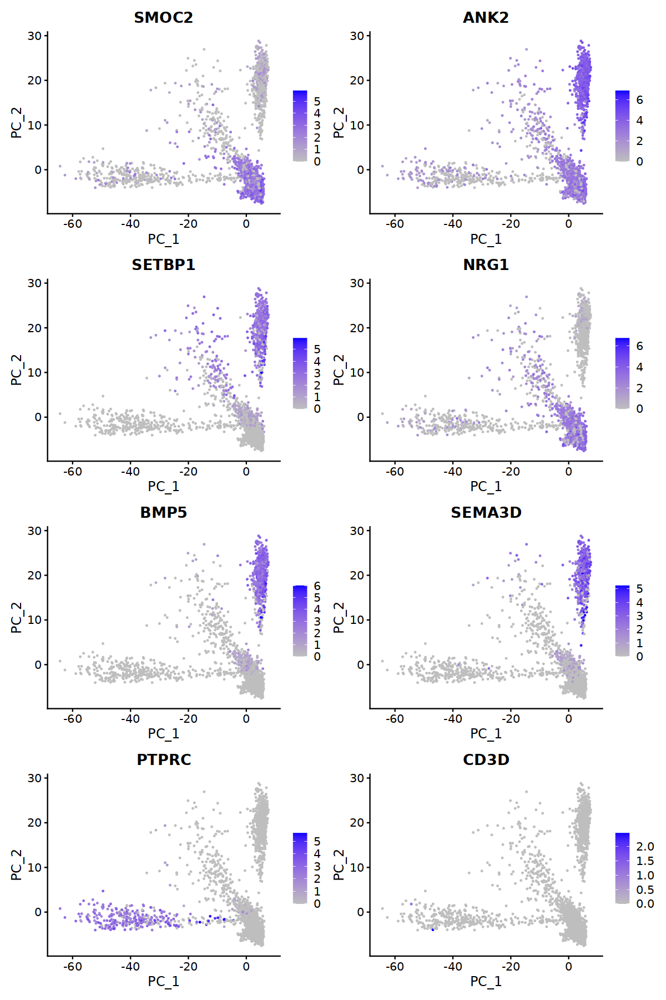

In [20]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

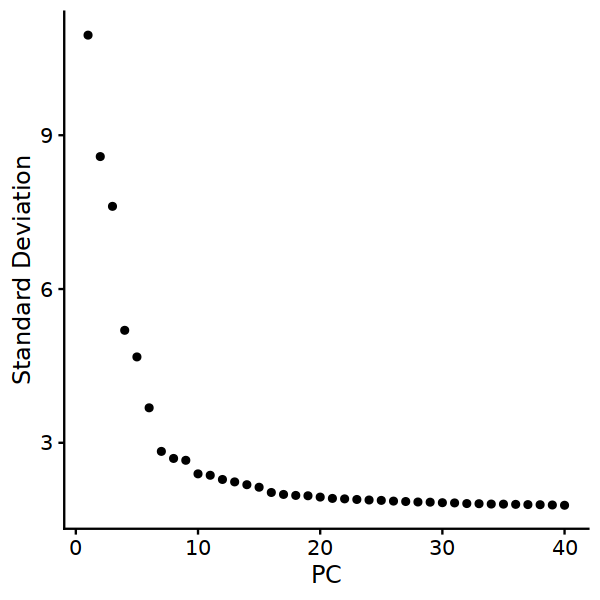

In [21]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=40)

In [22]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


14:56:46 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:46 Read 4960 rows and found 20 numeric columns

14:56:46 Using Annoy for neighbor search, n_neighbors = 30

14:56:46 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:46 Writing NN index file to temp file /scratch_tmp/49729482/Rtmp2gZeGl/file13d7929ac2fc7

14:56:46 Searching Annoy index using 1 thread, search_k = 3000

14:56:48 Annoy recall = 100%

14:56:49 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:49 28 smooth knn distance failures

14:56:50 Initializing from normalized Laplacian + noise (using irlba)

14:56:51 Commencing optimization for 500 epochs, with 210668 positive edges

14:57:05 Optimization f

In [23]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [24]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:57:18 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:19 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:57:21 Initializing from normalized Laplacian + noise (using irlba)

14:57:21 Commencing optimization for 500 epochs, with 150008 positive edges

14:57:36 Optimization finished



In [25]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4960
Number of edges: 181928

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9495
Number of communities: 9
Elapsed time: 0 seconds


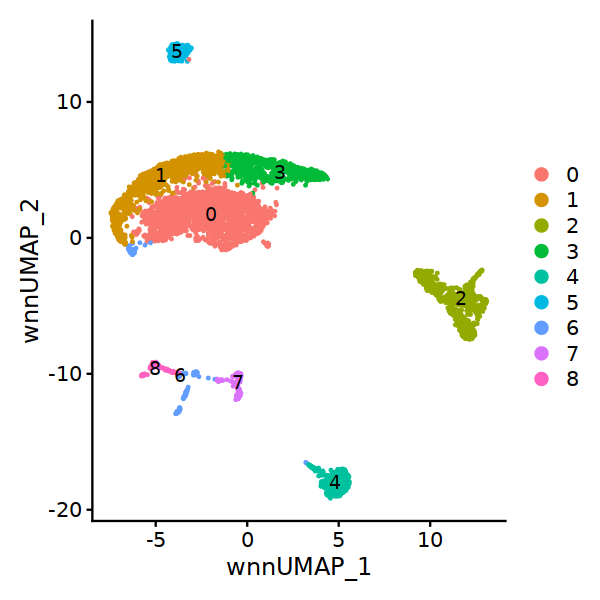

In [26]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [27]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



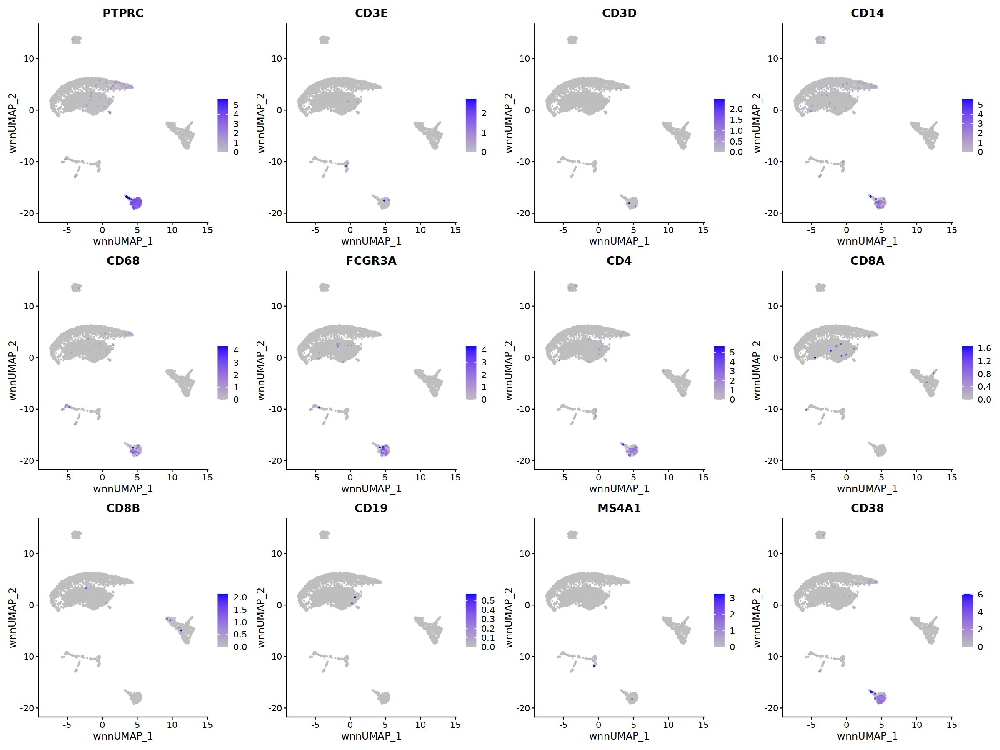

In [28]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

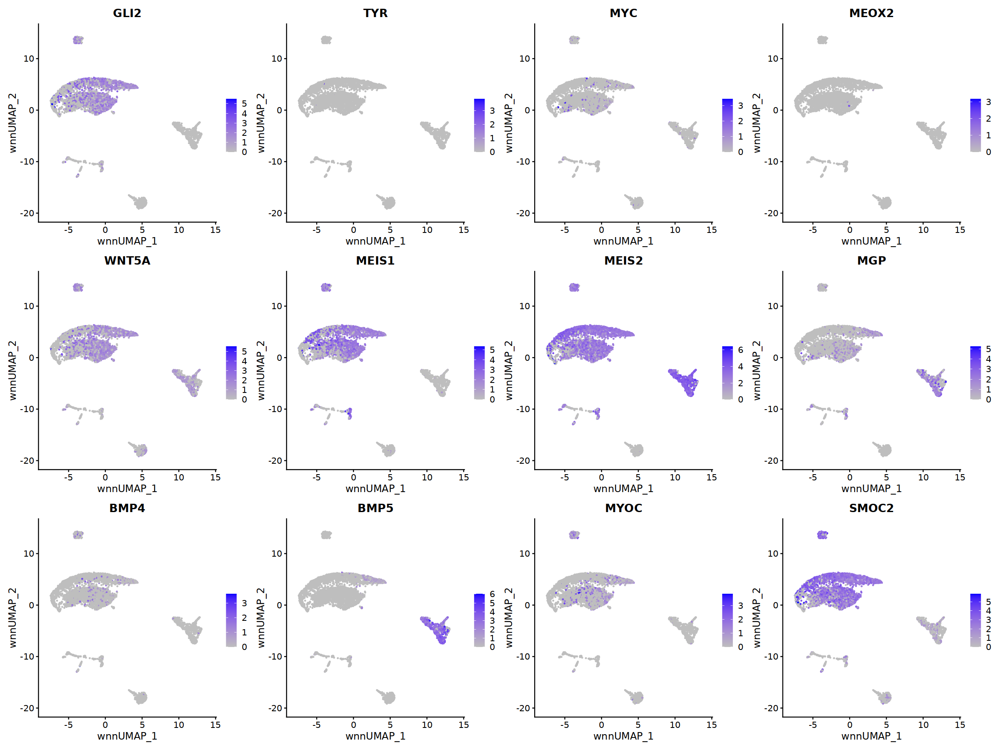

In [29]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

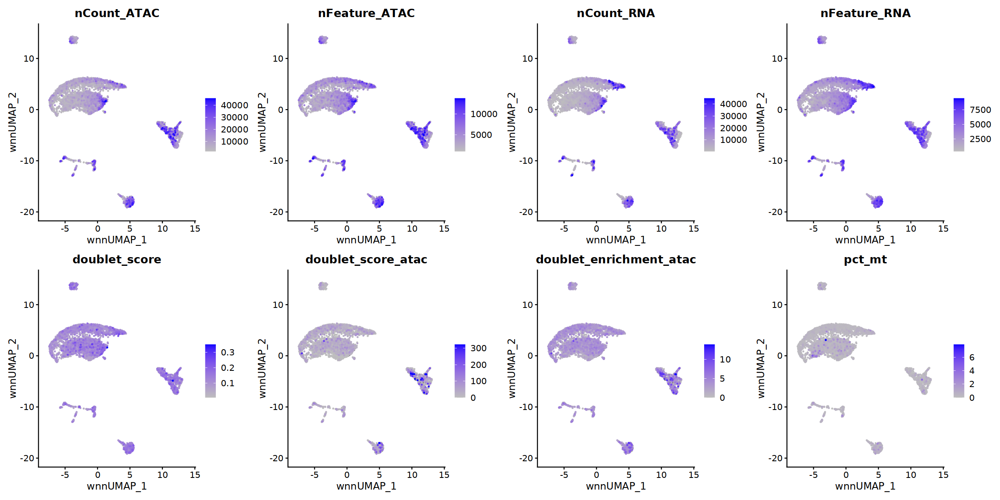

In [30]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

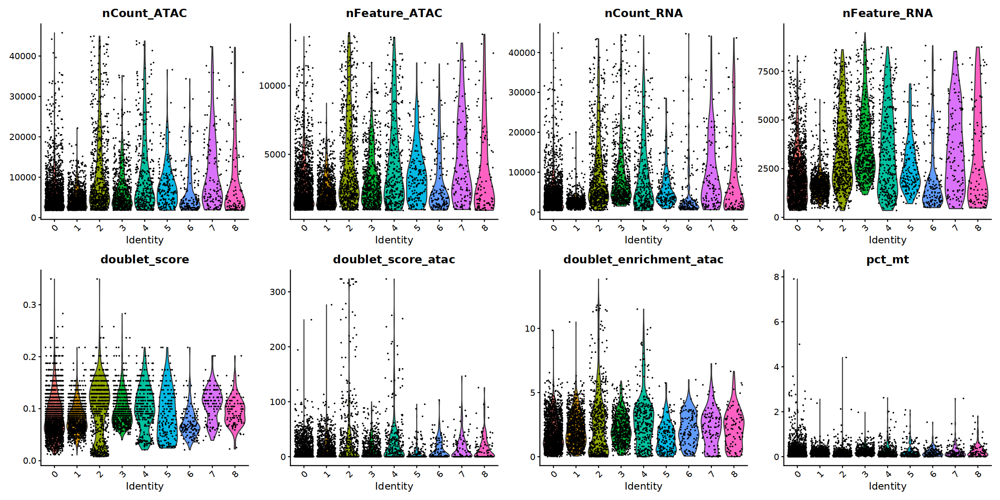

In [31]:
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

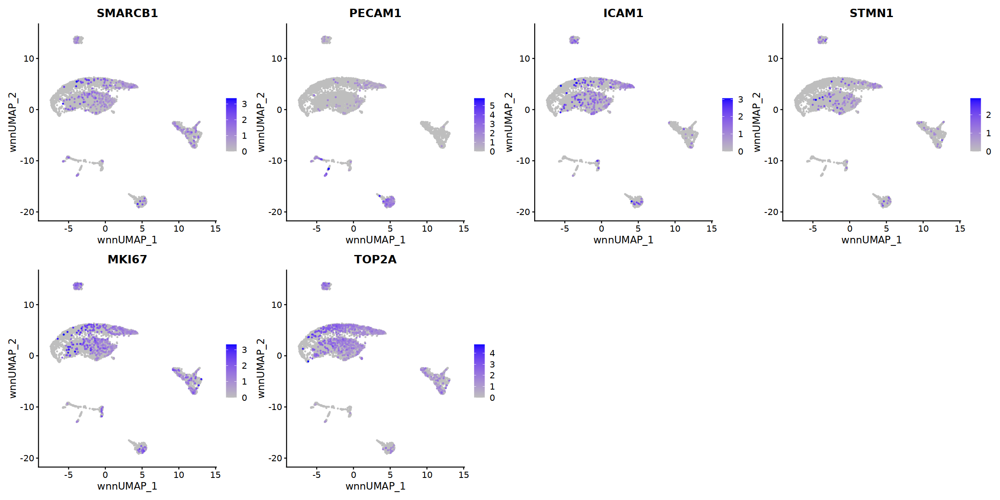

In [32]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

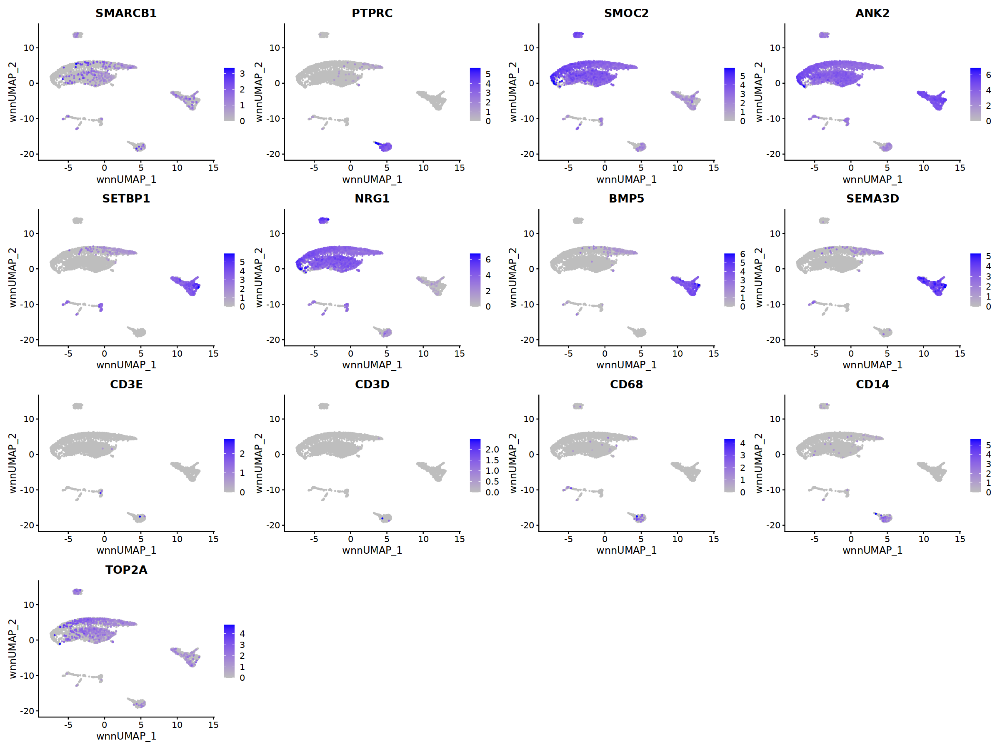

In [33]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC", "SMOC2","ANK2","SETBP1", 
                              "NRG1","BMP5","SEMA3D", "CD3E", "CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

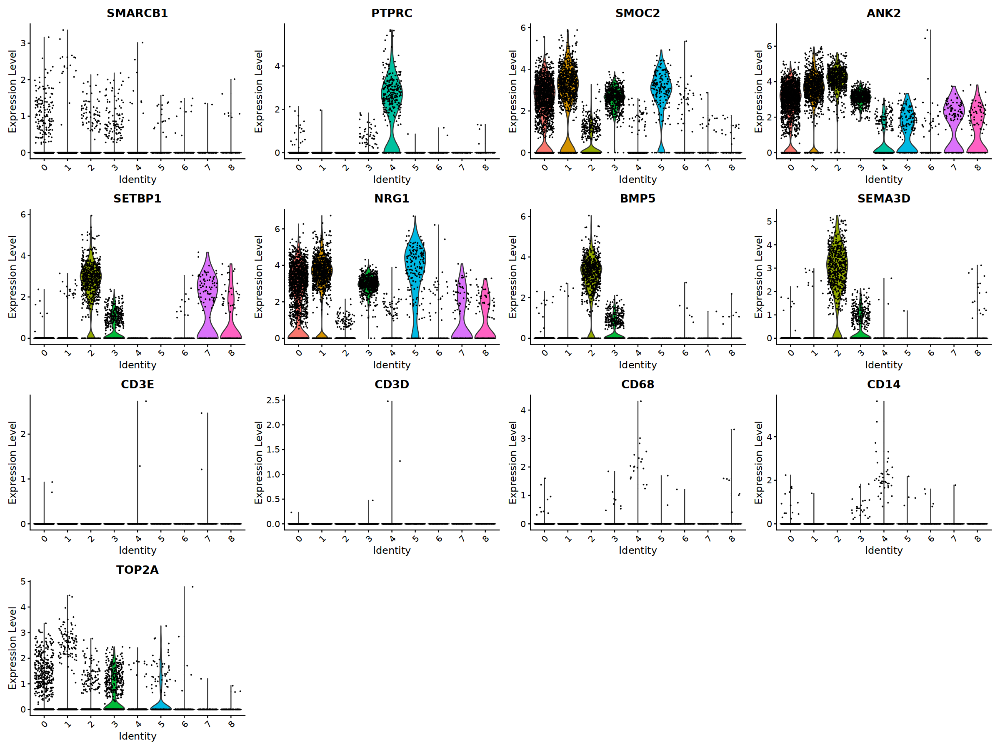

In [34]:
VlnPlot(seurat_obj,feature=vars2plot, ncol = 4)

## Filter cells

Cluster 6 low quality cells 

In [35]:
rna.markers %>% 
  dplyr::filter(cluster == "6") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
FLT1,3.166581e-77,4.512566,0.295,0.023,9.800567e-73,6,FLT1
VWF,1.049290e-86,4.146683,0.237,0.012,3.247551e-82,6,VWF
PLCB1,2.782726e-28,4.145773,0.353,0.093,8.612538e-24,6,PLCB1
MECOM,5.750067e-80,4.128415,0.324,0.027,1.779646e-75,6,MECOM
LDB2,6.013163e-75,4.117513,0.273,0.020,1.861074e-70,6,LDB2
KCNQ3,1.713525e-108,3.988239,0.245,0.009,5.303359e-104,6,KCNQ3
LINC01320,4.547629e-28,3.904769,0.173,0.022,1.407491e-23,6,LINC01320
ST6GALNAC3,1.977444e-94,3.755546,0.230,0.010,6.120190e-90,6,ST6GALNAC3
THSD7A,2.859621e-81,3.724410,0.209,0.010,8.850527e-77,6,THSD7A


Remove low quality cells and doublets from object

In [36]:
seurat_obj <- subset(seurat_obj, ident=6, invert=T)

## Re-process object after filtering

### RNA

In [37]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [38]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

In [39]:
sce

class: SingleCellExperiment 
dim: 30950 4821 
metadata(0):
assays(2): counts logcounts
rownames(30950): AL627309.1 AL627309.5 ... AC007325.4 AC007325.2
rowData names(0):
colnames(4821): AAACAGCCAATGAGGT-1 AAACAGCCAGCATTAT-1 ...
  TTTGTTGGTAACCACA-1 TTTGTTGGTTTAGCGA-1
colData names(38): orig.ident nCount_ATAC ... RNA_decontx.weight ident
reducedDimNames(3): PCA UMAP WNN.UMAP
mainExpName: RNA_decontx
altExpNames(2): RNA ATAC

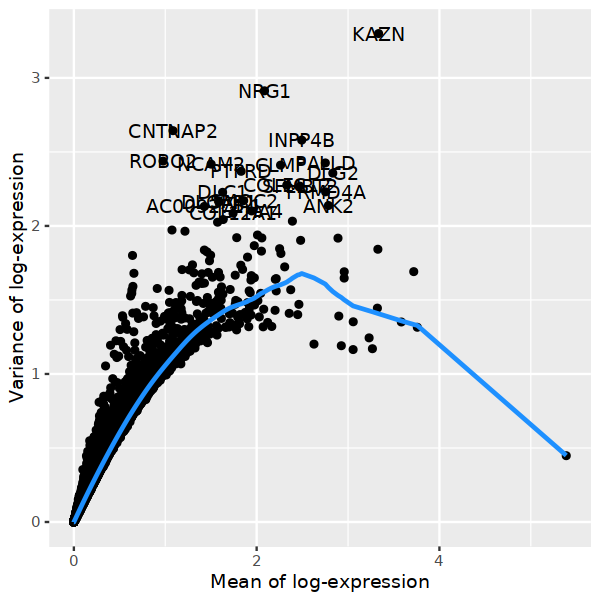

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [41]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  ERC2, RORA, ANK2, SNTG2, EYA4, CLMP, SMOC2, KAZN, LGR4, INPP4B 
	   PTPRD, COL12A1, NCAM2, NRG1, PALLD, TIMP3, DLC1, DLG2, AUTS2, MAGI1 
	   KIAA1211, PDE3A, AC009271.1, SDK2, DLGAP1, AL139383.1, HPSE2, KCNN3, AC116362.1, MEG8 
Negative:  LRMDA, PLXDC2, DPYD, DOCK8, PTPRC, SLC8A1, LDLRAD4, RAB31, DOCK4, DOCK2 
	   DOCK5, SLC16A10, SAMSN1, MSR1, FMN1, ATXN1, CHST11, FMNL2, ATP8B4, KYNU 
	   RBM47, TRPS1, GLUL, IQGAP2, DOCK10, SRGN, TBXAS1, VAV3, ITGAX, ABCA1 
PC_ 2 
Positive:  BMP5, NR2F1-AS1, CFH, SETBP1, KCNT2, RARB, UNC5C, DMD, MDGA2, SEMA3D 
	   L3MBTL4, RALYL, PRICKLE1, AC092422.1, ADAMTS20, MIR548XHG, EPHA7, KIAA0825, TMPRSS15, PLEKHA5 
	   KCNK2, ARHGAP28, NR2F1, FSTL5, PLPP1, CNTNAP2, AC078881.1, COLGALT2, BNC2, ROBO2 
Negative:  KAZN, SFMBT2, FRMD4A, PALLD, INPP4B, COLEC12, AUTS2, CLMP, DLG2, EPHA4 
	   PTPRD, NRG1, COL12A1, SMOC2, NHSL1, RORA, AC009271.1, KCNN3, SDK2, KIAA1211 
	   AL139383.1, CAMK1D, ESRRB, GRAMD1B, MEIS1, 

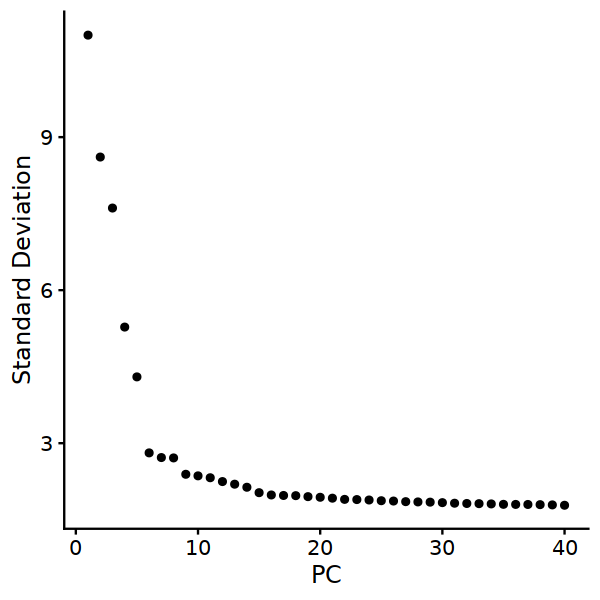

In [42]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [43]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [44]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



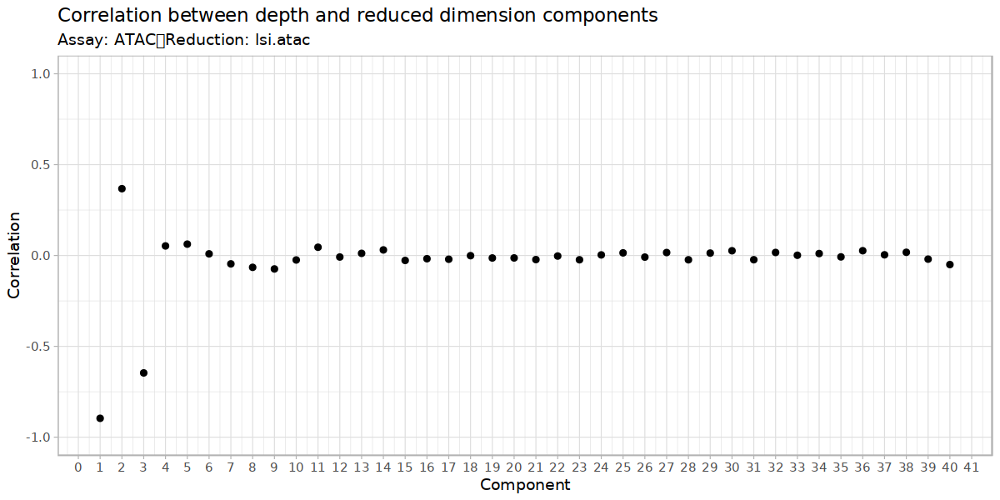

In [45]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

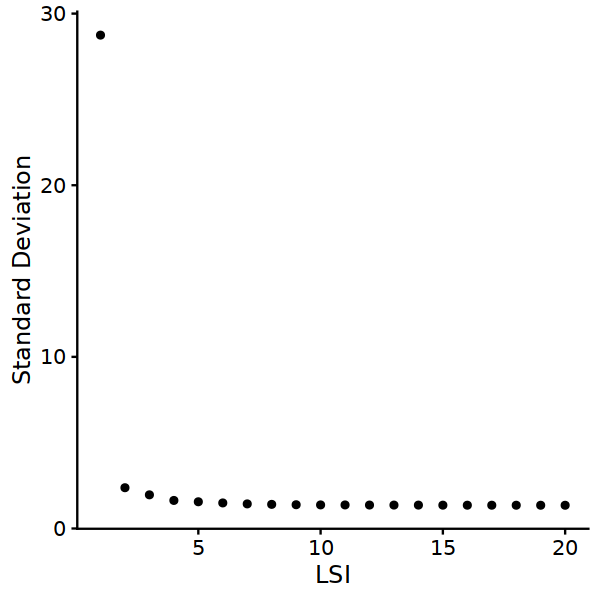

In [46]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [47]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [48]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

15:01:12 UMAP embedding parameters a = 0.115 b = 1.929

15:01:13 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:01:14 Initializing from normalized Laplacian + noise (using irlba)

15:01:14 Commencing optimization for 500 epochs, with 147176 positive edges

15:01:29 Optimization finished



Very low resolution for clustering since some clusters from the previous clustering did not show major marker differences

In [49]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.02,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4821
Number of edges: 178402

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9899
Number of communities: 6
Elapsed time: 0 seconds


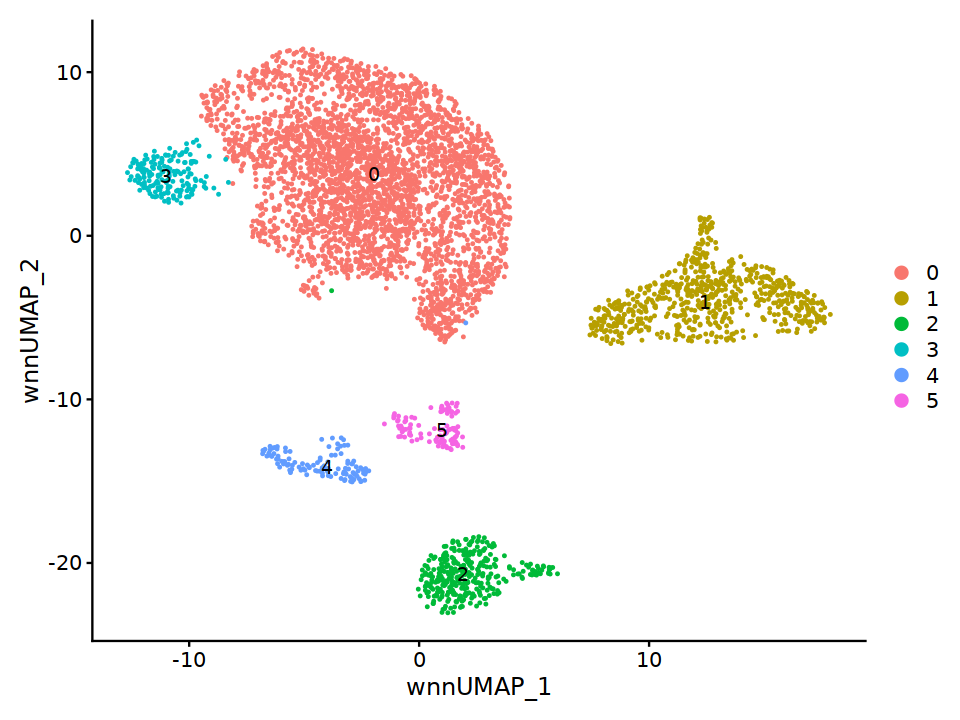

In [50]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [51]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5



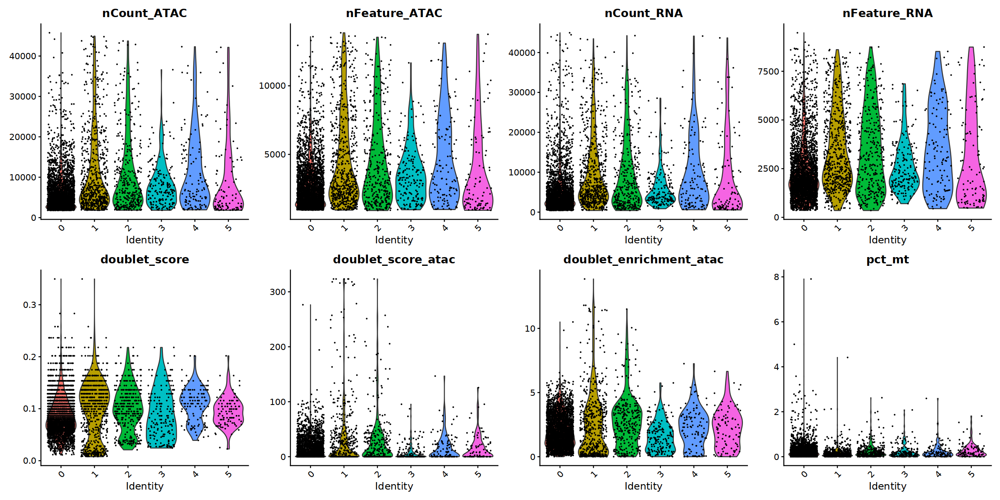

In [52]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

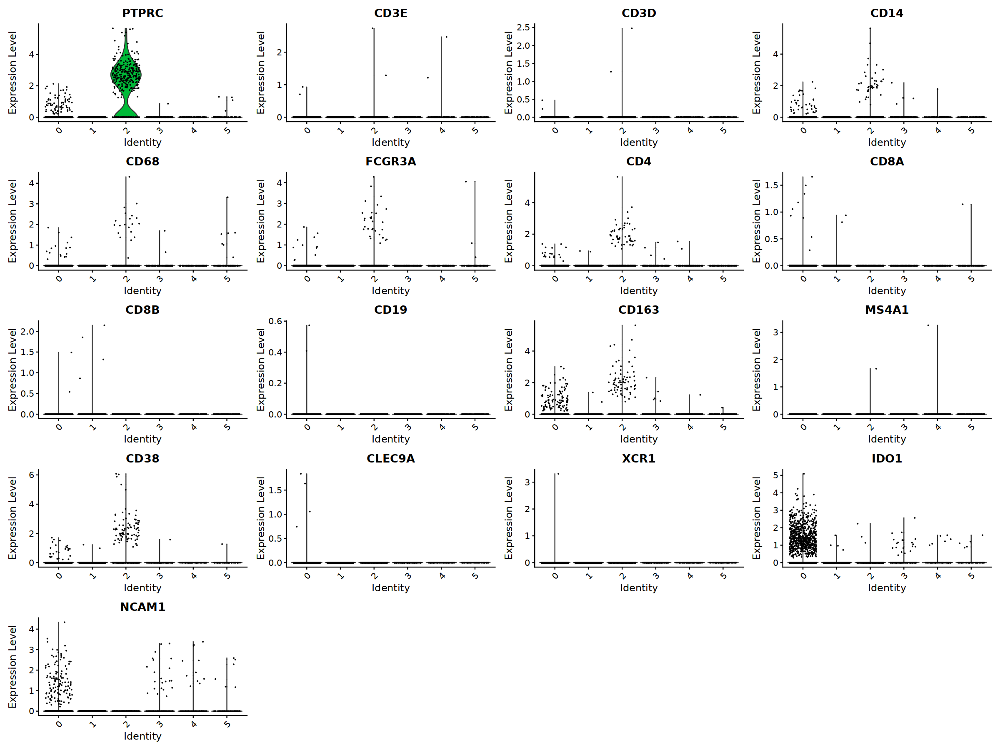

In [53]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", 
            "CD4", "CD8A", "CD8B", "CD19", "CD163",
            "MS4A1", "CD38", "CLEC9A","XCR1","IDO1", "NCAM1")

vars2plot <- exp_genes_plot(immune, seurat_obj)

VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

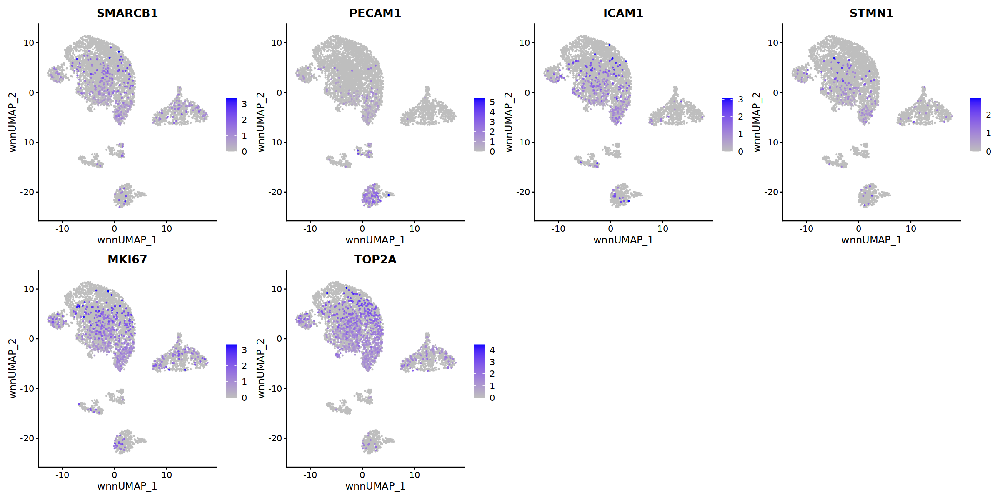

In [54]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1",
           "MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

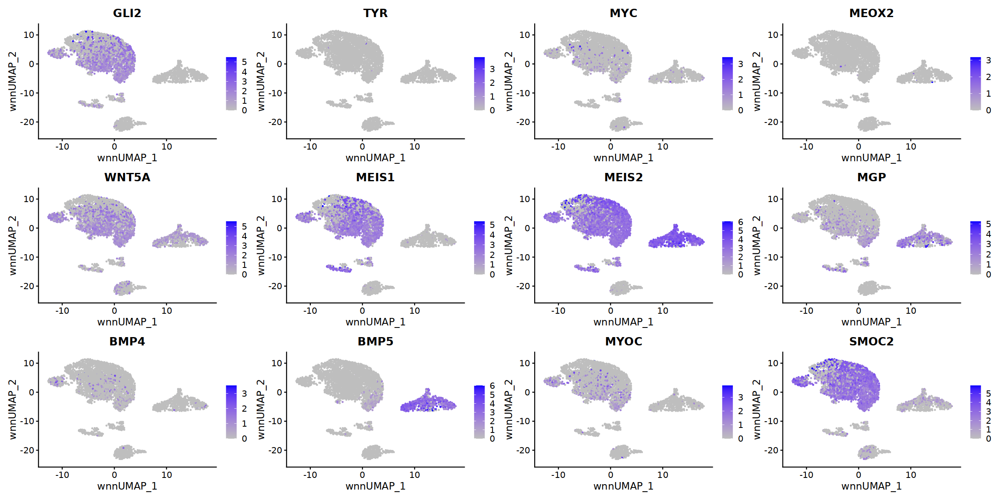

In [55]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

In [56]:
rna.markers %>% 
  dplyr::filter(cluster == "5") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
KCNIP41,5.607575e-237,5.248692,0.79,0.042,1.735544e-232,5,KCNIP4
ERBB4,3.676764e-160,4.886643,0.67,0.047,1.137959e-155,5,ERBB4
PKHD1,0.000000e+00,4.748255,0.66,0.007,0.000000e+00,5,PKHD1
MECOM1,0.000000e+00,4.741947,0.69,0.013,0.000000e+00,5,MECOM
BICC11,5.476930e-125,4.707828,0.84,0.114,1.695110e-120,5,BICC1
AC019197.1,1.306771e-247,4.238520,0.43,0.007,4.044457e-243,5,AC019197.1
NHS1,7.988762e-180,4.165105,0.58,0.028,2.472522e-175,5,NHS
FAM155A,1.977985e-107,4.002832,0.43,0.027,6.121865e-103,5,FAM155A
PLCB1,9.017299e-104,3.998058,0.67,0.080,2.790854e-99,5,PLCB1


Cluster 2 immune cells 

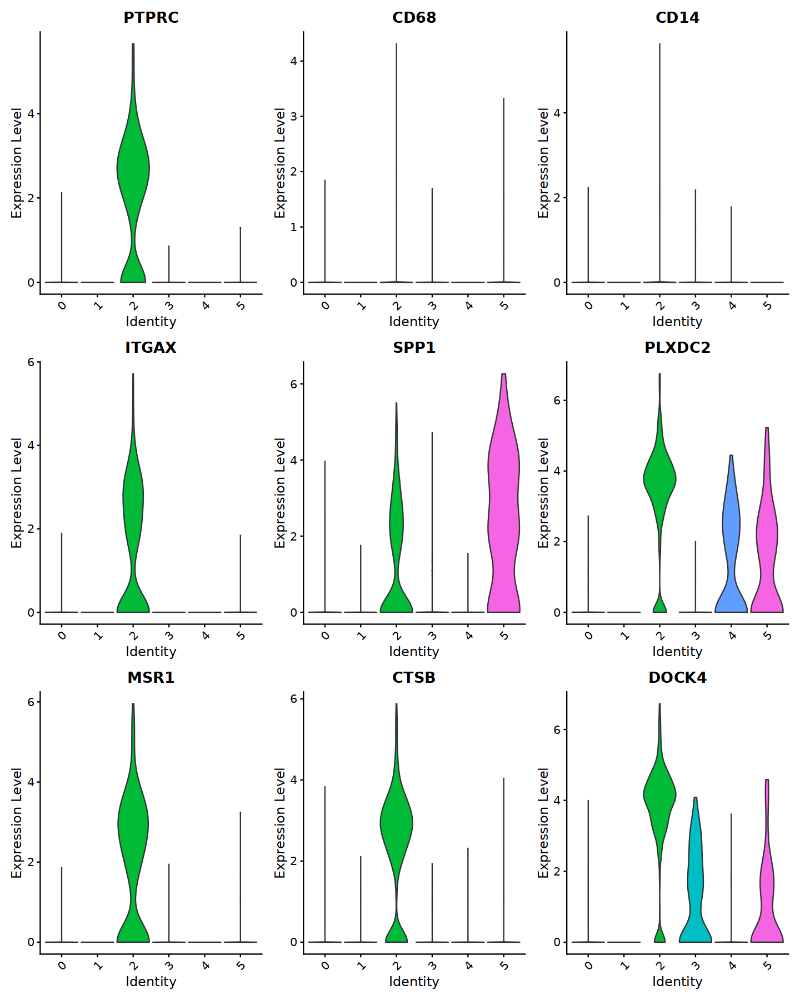

In [57]:
options(repr.plot.width = 12, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PTPRC","CD68", "CD14", 
                              "ITGAX", "SPP1", "PLXDC2",
                              "MSR1", "CTSB", "DOCK4"), 
        ncol = 3, pt.size=0)

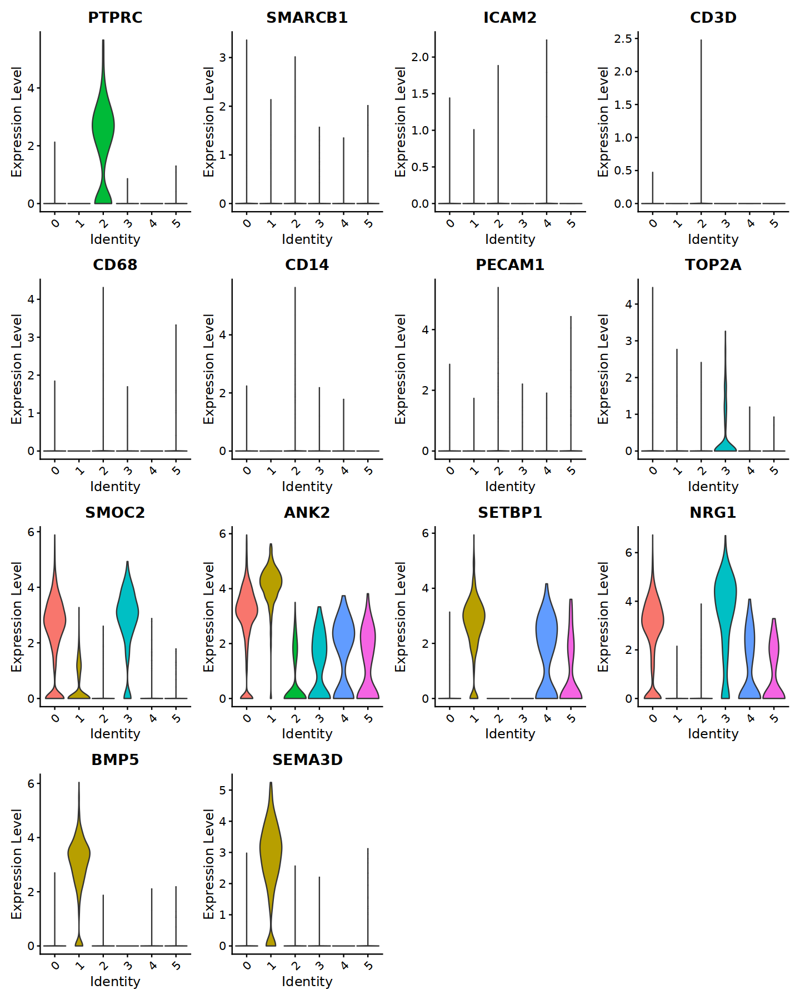

In [58]:
options(repr.plot.width = 12, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PTPRC", "SMARCB1", "ICAM2", "CD3D",
                              "CD68", "CD14", "PECAM1", "TOP2A",
                              "SMOC2","ANK2","SETBP1", 
                              "NRG1","BMP5","SEMA3D"), 
        ncol = 4, pt.size=0)

### Rename

In [59]:
rename_clusters <- c("0"="Tumor SMOC2", "1"="Tumor ROBO2",
                     "2"= "Monocytes-Macrophages", "3"="Tumor SEMA5A", 
                     "4"="Fibroblast", "5"="Tumor ERBB4")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [60]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [61]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [62]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [63]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [64]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune

Calculating cluster Other stromal



In [65]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

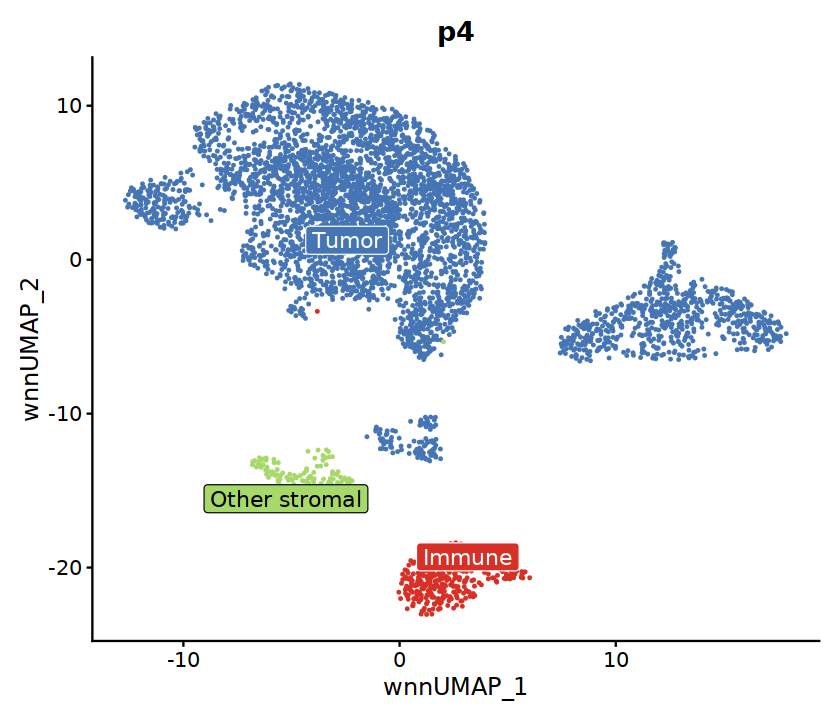

In [66]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [67]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [68]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [69]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

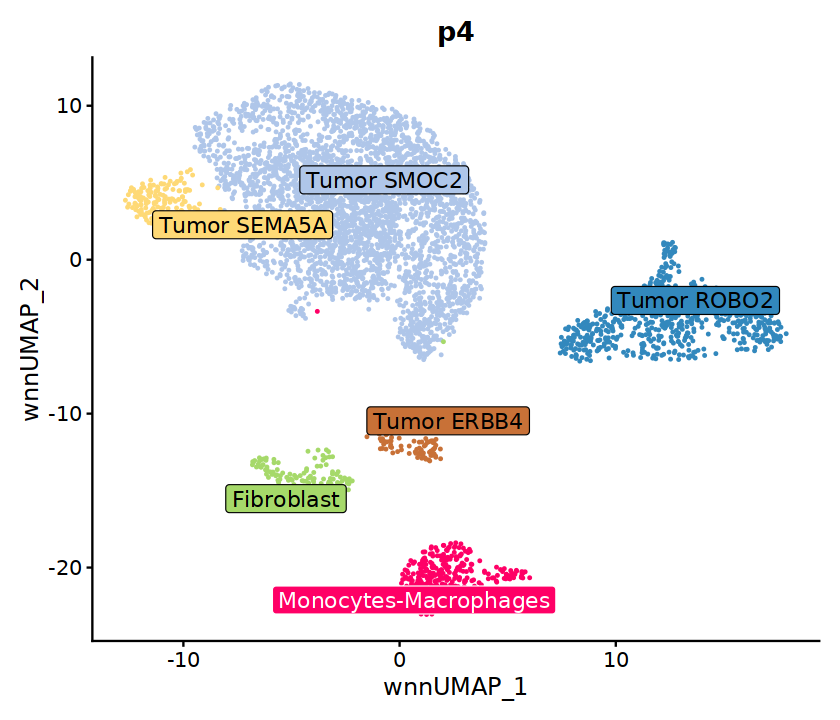

In [70]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [71]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

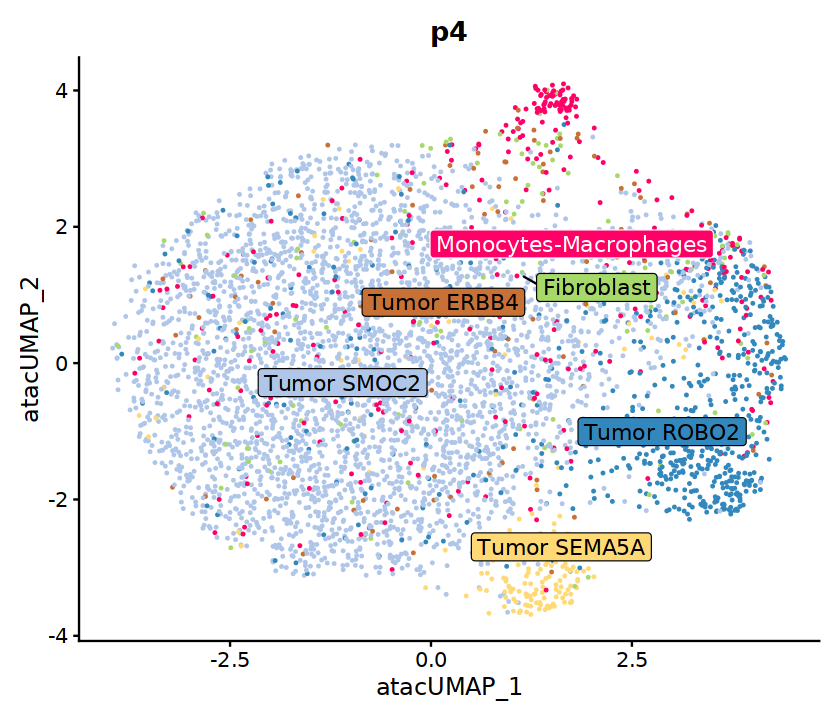

In [72]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [73]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

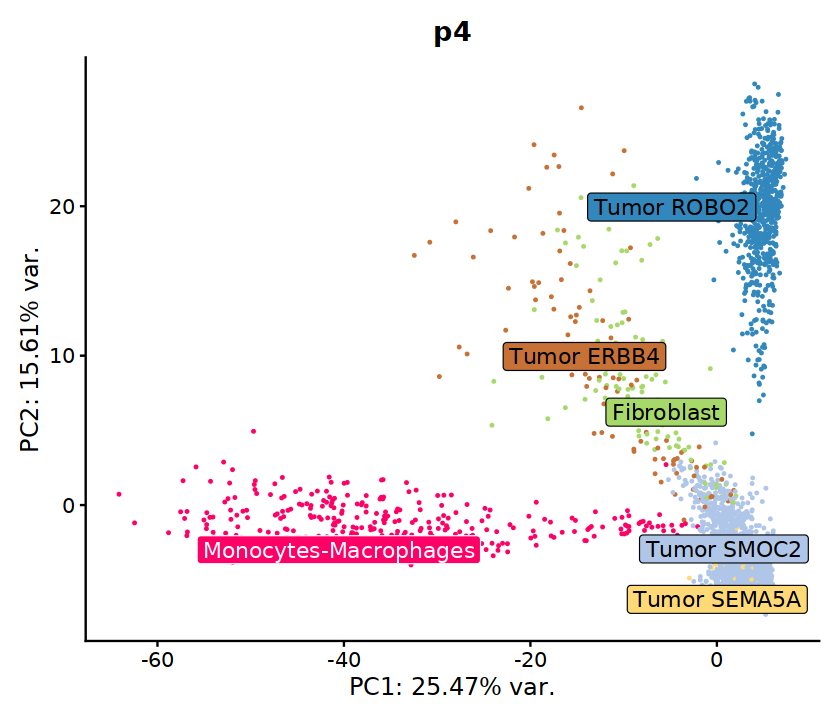

In [74]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

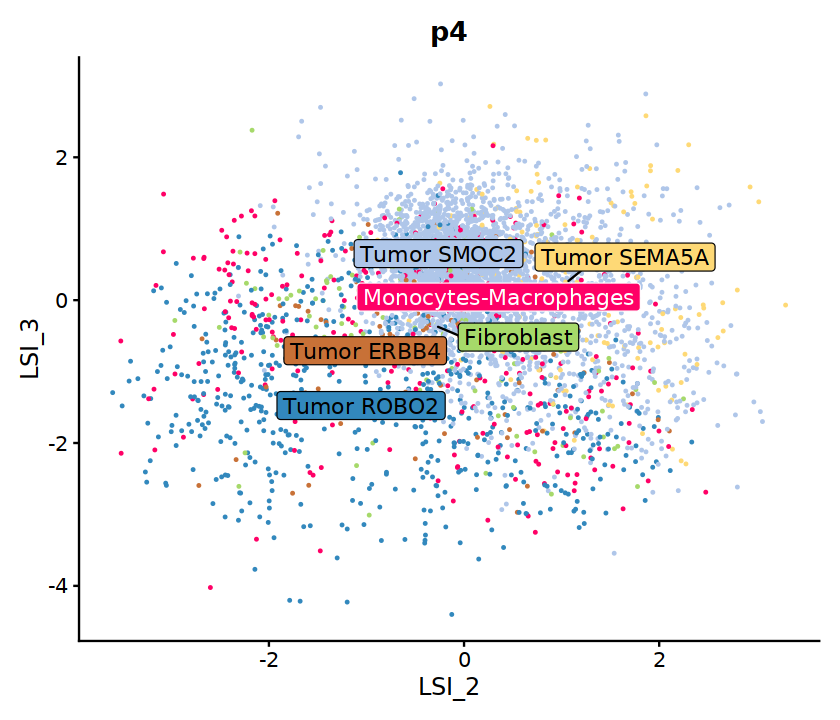

In [75]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

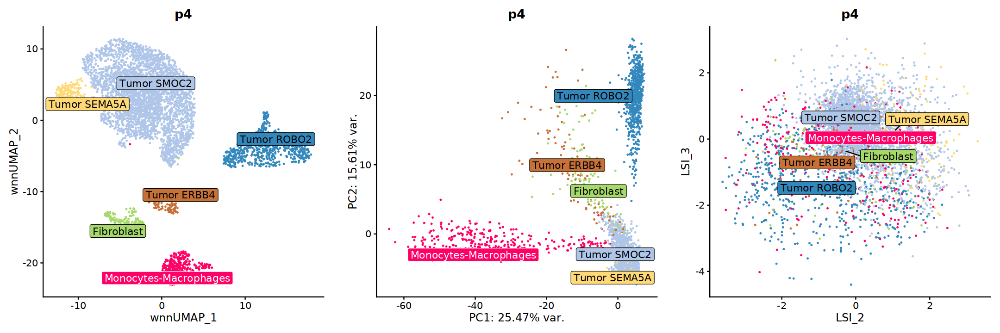

In [76]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [77]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [78]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEIS2","ANK2","EYA4"), markers) ## common markers to all clusters

In [79]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

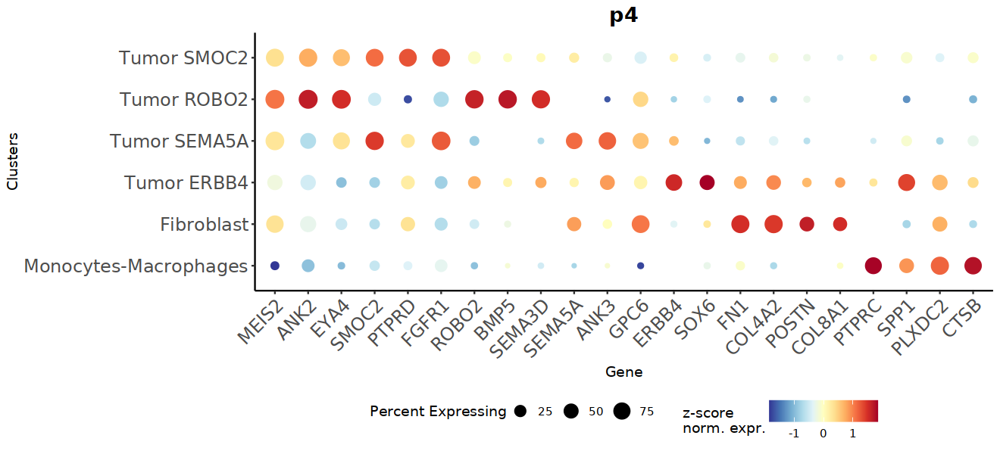

In [80]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

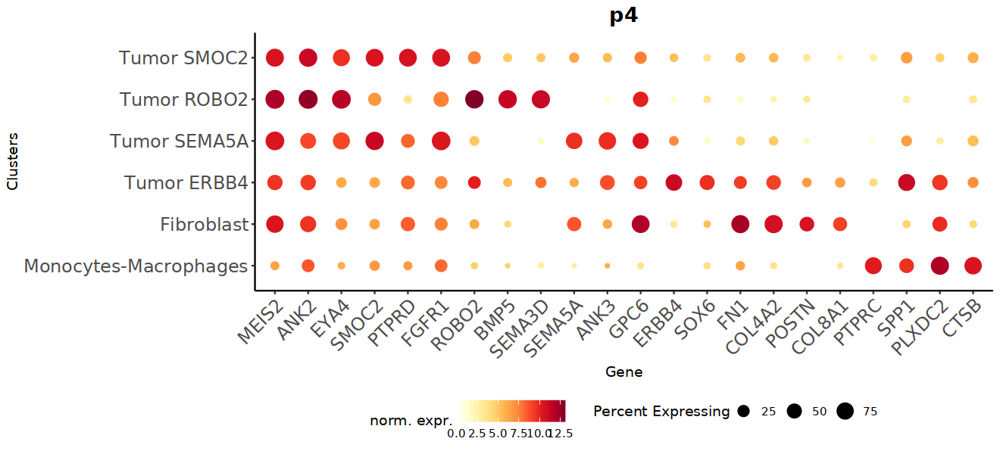

In [81]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [82]:
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [83]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [84]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [85]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [86]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    